<a href="https://colab.research.google.com/github/xen212/ML_Machine_Learning/blob/main/Final_Project_Option2_Tabular_NN_vs_Classical_Xen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

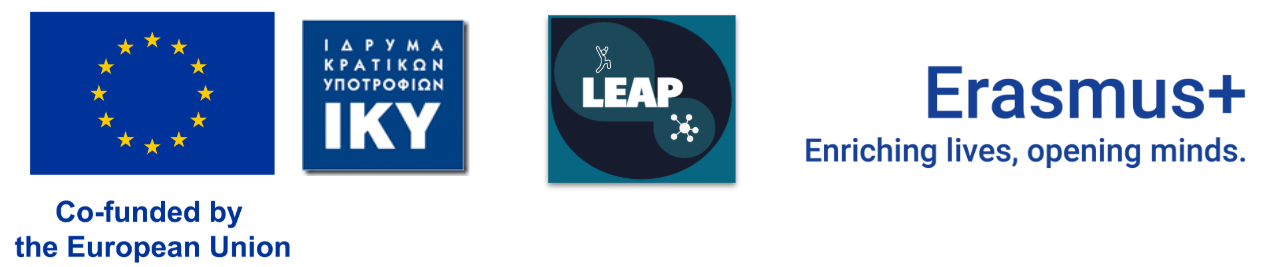

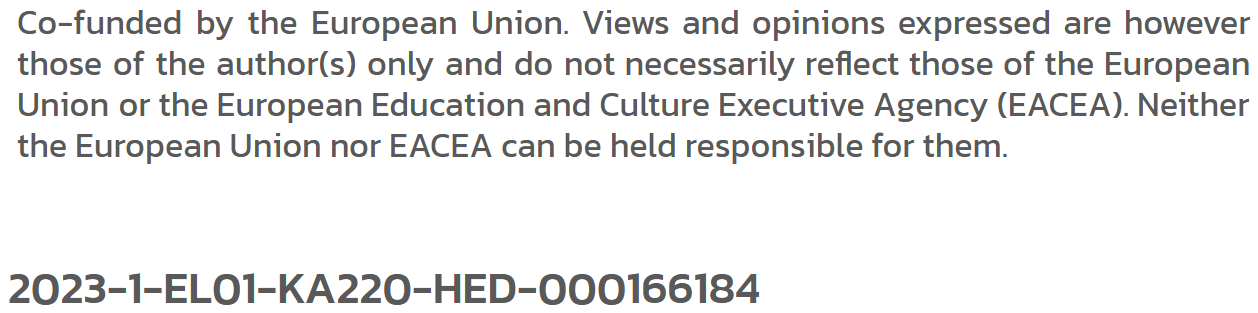

# Final Project, Option 2: Does a neural network beat a classical model?

A public agency wants to flag likely higher-income households from survey data, so that an outreach programme can be targeted, and it must choose between a simple, explainable model and a more complex neural network. In this project you build both and judge whether the added complexity is worthwhile.

In this project you build two classifiers for the same real data set, then compare them fairly.

**Central question:** does a neural network beat a well-built classical model on this data set?

The data set is Adult, also called Census Income. Each row describes one person, with a mix of numeric features (such as age and hours worked per week) and categorical features (such as occupation and education). The task is to predict whether that person earns more than 50,000 dollars a year.

This project draws on two earlier modules. In Module 3, we built a preprocessing and modelling pipeline in scikit-learn, using a ColumnTransformer to impute missing values, scale the numeric features, and one-hot encode the categorical ones, and we judged the result with cross-validation. In Module 5, we built and trained dense neural networks in Keras. Here you build one of each on the same features and see which does better.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, the target encoding, the train and test split, and the detection of which columns are numeric and which are categorical. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import keras
from keras import layers

### Loading the data

We download the Adult data set from OpenML. The features arrive in `X` as a table, and the target in `y` as text, either `>50K` or `<=50K`. The download runs once and may take a moment.

In [ ]:
X, y = fetch_openml("adult", version=2, as_frame=True, return_X_y=True)

print("Rows and columns:", X.shape)
print("Target values:", y.value_counts().to_dict())
X.head()

Rows and columns: (48842, 14)
Target values: {'<=50K': 37155, '>50K': 11687}


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


### Encoding the target

The target is text with two values. We convert it to numbers so both models can use it. `LabelEncoder` maps the two classes to 0 and 1 in alphabetical order, so `<=50K` becomes 0 and `>50K` becomes 1. The higher income class is therefore the positive class, labelled 1.

In [ ]:
y = LabelEncoder().fit_transform(y)
print("Positive rate (share earning >50K):", round(y.mean(), 3))

Positive rate (share earning >50K): 0.239


### Train and test split

We split the data into a training set and a test set before doing anything else, and we keep the class balance with `stratify`, exactly as in Module 3. Both models are trained on the training set and judged on the same held-back test set, so the comparison is fair.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training rows:", X_train.shape[0])
print("Test rows:    ", X_test.shape[0])

Training rows: 39073
Test rows:     9769


### Numeric and categorical columns

The two kinds of feature need different preprocessing, so we sort the columns into a numeric group and a categorical group. We detect them from the column data types.

In [ ]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)

Numeric features:     ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## Part B. The classical model

From here on, the cells are yours to complete.

First, build the preprocessing step, the same idea you used in Module 3. Numeric and categorical columns are handled by separate small pipelines, then joined with a ColumnTransformer.

In [ ]:
# Build the preprocessor with a ColumnTransformer.

numeric_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess = ColumnTransformer(transformers=[
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

### The full pipeline

Wrap the preprocessor and a classifier into a single pipeline. We use `LogisticRegression`, the classifier from Module 3.

In [ ]:
# Combine the preprocessor and a LogisticRegression into one Pipeline,
# so that preprocessing is fitted only on the training data inside each fold.
# LogisticRegression(max_iter=1000) gives it enough iterations to converge.

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

### Cross-validation

Before the final test, estimate performance with cross-validation on the training data, as in Module 3. A single split can be lucky or unlucky; averaging over folds gives a steadier estimate.

In [ ]:
# Run 5-fold cross-validation on the TRAINING data, scoring by F1.
# Use StratifiedKFold(n_splits=5, shuffle=True, random_state=42).

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='f1')

print("CROSS-VALIDATION (F1)")
print("-" * 40)
print("Fold scores:", np.round(cv_scores, 4))
print("Mean ± Std: ", np.round(cv_scores.mean(), 4), "±", np.round(cv_scores.std(), 4))

CROSS-VALIDATION (F1)
----------------------------------------
Fold scores: [0.6714 0.6665 0.6528 0.6454 0.6517]
Mean ± Std:  0.6576 ± 0.0098


### Fit and evaluate on the test set

Now fit the pipeline on the whole training set and judge it on the test set. Record the accuracy and the F1 score, and draw the confusion matrix. Keep these numbers; you will compare them with the network in Part D.

CLASSICAL MODEL EVALUATION
----------------------------------------
Accuracy: 0.8524
F1 Score: 0.6562

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7431
        >50K       0.74      0.59      0.66      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769



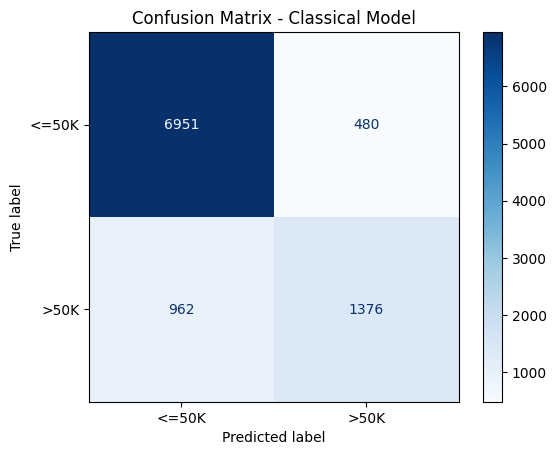

In [ ]:
# Fit clf on the training data, then predict on the test data.
from sklearn.metrics import classification_report

clf.fit(X_train, y_train)
clf_pred = clf.predict(X_test)

# Store the results so you can compare them later:
clf_acc = accuracy_score(y_test, clf_pred)
clf_f1  = f1_score(y_test, clf_pred)

print("CLASSICAL MODEL EVALUATION")
print("-" * 40)
print(f"Accuracy: {clf_acc:.4f}")
print(f"F1 Score: {clf_f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, clf_pred, target_names=['<=50K', '>50K']))

# Then draw the confusion matrix for the classical model.
cm = confusion_matrix(y_test, clf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50K', '>50K'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Classical Model")
plt.show()

## Part C. The neural network

Before building the neural network, make a prediction. Do you expect its F1 score to be higher than, lower than, or similar to that of logistic regression? Do you expect a large or a small difference? Briefly explain your reasoning.

ANSWER

The neural network is expected to show slightly improved performance (expressed by the F1 score) compared to the classical network.

This is because, on the one hand, the Adult dataset consists of structured records, and therefore Logistic Regression, using the standard preprocessing, is sufficient to analyze the data satisfactorily; on the other hand, the size of the dataset is such that it does not require a complex neural network for its analysis. Nevertheless, the neural network, by using functions such as ReLU, a sigmoid output and binary cross-entropy loss, dropout and early stopping, can identify certain nonlinear interactions among the features (e.g., the combination of age, education, and working hours) that the classical network cannot directly capture; therefore, a slight increase in the F1 score is expected.


A neural network needs a plain numeric array as input, so we apply the preprocessor to turn the mixed table into numbers. We fit the preprocessor on the training data only, then transform both sets, so no information leaks from the test set.

In [ ]:
# Turn the tables into numeric arrays the network can read.
#   X_train_prep = preprocess.fit_transform(X_train)   # fit on training data only
#   X_test_prep  = preprocess.transform(X_test)         # reuse the same fitting
# Then print X_train_prep.shape so you know how many input features the network needs.
#
# TODO: create X_train_prep and X_test_prep, and print the training shape.
X_train_prep = preprocess.fit_transform(X_train)
X_test_prep  = preprocess.transform(X_test)

print("Preprocessed training data shape:", X_train_prep.shape)
print("Preprocessed test data shape:    ", X_test_prep.shape)


Preprocessed training data shape: (39073, 105)
Preprocessed test data shape:     (9769, 105)


### Build the network

Build a small dense network for this feature array, in the Sequential style from Module 5. The task is binary, so the output is a single unit with a sigmoid activation, giving the probability of the positive class.

In [ ]:
# Build a dense network with the Keras Sequential API with stronger regularization.
from keras import regularizers

net = keras.Sequential([
    layers.Input(shape=(X_train_prep.shape[1],)),

    # First hidden layer with L2 regularization
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.4),

    # Second hidden layer with L2 regularization
    layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.4),

    # Output layer
    layers.Dense(1, activation='sigmoid')
])

net.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │         3,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,937 (15.38 KB)

 Trainable params: 3,937 (15.38 KB)

 Non-trainable params: 0 (0.00 B)

### Compile and train

Compile and train the network. Because the output is a single sigmoid unit, the loss is `binary_crossentropy`. Use EarlyStopping so training stops once the validation loss stops improving.

Epoch 1/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7960 - loss: 0.4413 - val_accuracy: 0.8347 - val_loss: 0.3526
Epoch 2/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8385 - loss: 0.3576 - val_accuracy: 0.8470 - val_loss: 0.3406
Epoch 3/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8444 - loss: 0.3429 - val_accuracy: 0.8493 - val_loss: 0.3364
Epoch 4/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8486 - loss: 0.3366 - val_accuracy: 0.8511 - val_loss: 0.3378
Epoch 5/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8493 - loss: 0.3330 - val_accuracy: 0.8498 - val_loss: 0.3365
Epoch 6/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8522 - loss: 0.3288 - val_accuracy: 0.8526 - val_loss: 0.3362
Epoch 7/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8520 - loss: 0.3300 - val_accuracy: 0.8526 - val_loss: 0.3368
Epoch 8/20
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8530 - loss: 0.3260 - val_accuracy: 0.

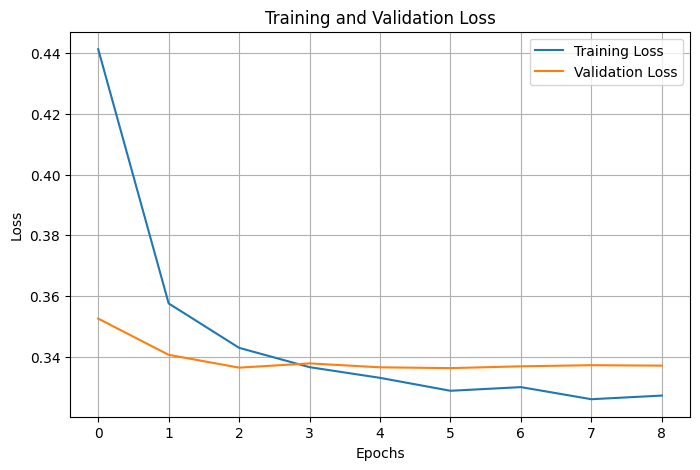

In [ ]:
# Compile net with:
#   optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
# Then train it with:
#   validation_split=0.1, an EarlyStopping callback (monitor "val_loss",
#   patience about 3, restore_best_weights=True), up to about 20 epochs,
#   and batch_size=128. Store the result in history.


net.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = net.fit(
    X_train_prep, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

# Σχεδίαση του γραφήματος απώλειας (loss curve)
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Evaluate on the test set

Judge the network on the same test set. The network outputs probabilities, so a prediction is positive when the probability is above 0.5. Record the accuracy and F1, and draw the confusion matrix.

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
NEURAL NETWORK EVALUATION
----------------------------------------
Accuracy: 0.8571
F1 Score: 0.6712

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7431
        >50K       0.75      0.61      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



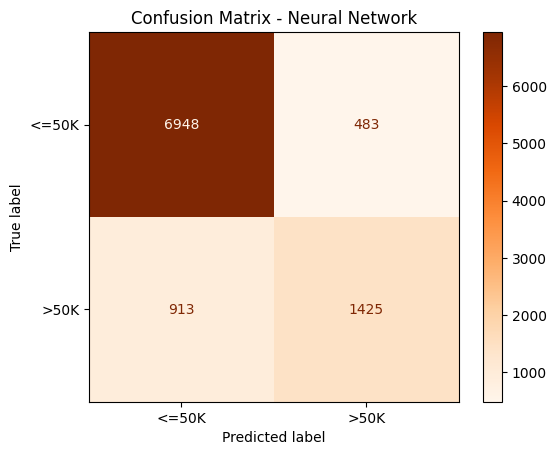

In [ ]:
# Produce predictions and evaluate the network.
nn_prob = net.predict(X_test_prep).ravel()     # probabilities
nn_pred = (nn_prob > 0.5).astype(int)           # threshold at 0.5

# Compute nn_acc and nn_f1
nn_acc = accuracy_score(y_test, nn_pred)
nn_f1  = f1_score(y_test, nn_pred)

print("NEURAL NETWORK EVALUATION")
print("-" * 40)
print(f"Accuracy: {nn_acc:.4f}")
print(f"F1 Score: {nn_f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, nn_pred, target_names=['<=50K', '>50K']))

# Draw the confusion matrix for the neural network
cm_nn = confusion_matrix(y_test, nn_pred)
disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=['<=50K', '>50K'])
disp_nn.plot(cmap='Oranges')
plt.title("Confusion Matrix - Neural Network")
plt.show()

## Part D. The comparison

Now answer the central question. You have four numbers: the accuracy and F1 of the classical model, and the accuracy and F1 of the network, all measured on the same test set. Because the higher-income class is the minority class, use F1 as your main comparison metric and accuracy as supporting information.

               Metric  Logistic Regression  Neural Network
   F1 Score (Primary)             0.656175        0.671220
Accuracy (Supporting)             0.852390        0.857099


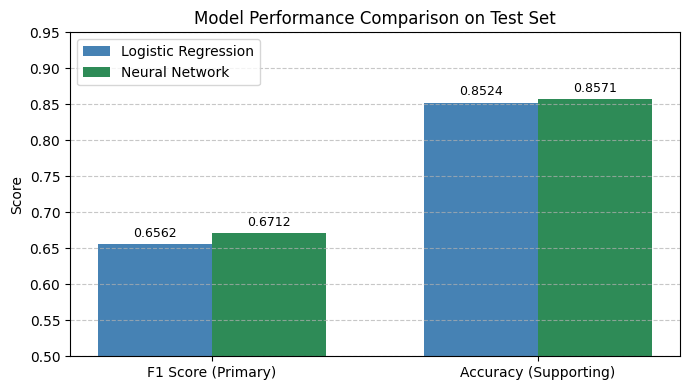

In [ ]:
# Compare the two models side by side.
# Print clf_acc and clf_f1 next to nn_acc and nn_f1, or draw a small bar chart.
# Lead with F1 in your comparison, but report both metrics.
#
# TODO: display the comparison.
# Side-by-side comparison table and visualization

comparison_df = pd.DataFrame({

    "Metric": ["F1 Score (Primary)", "Accuracy (Supporting)"],

    "Logistic Regression": [clf_f1, clf_acc],

    "Neural Network": [nn_f1, nn_acc]

})



print(comparison_df.to_string(index=False))



# Plot comparison bar chart

fig, ax = plt.subplots(figsize=(7, 4))

x = np.arange(len(comparison_df["Metric"]))

width = 0.35



ax.bar(x - width/2, comparison_df["Logistic Regression"], width, label="Logistic Regression", color="steelblue")

ax.bar(x + width/2, comparison_df["Neural Network"], width, label="Neural Network", color="seagreen")



ax.set_ylabel("Score")

ax.set_title("Model Performance Comparison on Test Set")

ax.set_xticks(x)

ax.set_xticklabels(comparison_df["Metric"])

ax.set_ylim(0.5, 0.95)

ax.legend()

ax.grid(axis="y", linestyle="--", alpha=0.7)



for i in x:

    ax.text(i - width/2, comparison_df.loc[i, "Logistic Regression"] + 0.01, f"{comparison_df.loc[i, 'Logistic Regression']:.4f}", ha='center', fontsize=9)

    ax.text(i + width/2, comparison_df.loc[i, "Neural Network"] + 0.01, f"{comparison_df.loc[i, 'Neural Network']:.4f}", ha='center', fontsize=9)



plt.tight_layout()

plt.show()

### Ethical considerations

This data set includes attributes such as sex, race, and nationality, and the target is a person's income bracket. A model that predicts income from these features can easily reproduce and entrench existing inequalities.

**Write two or three sentences here** on the ethical risks of deploying such a model. Consider fairness across the groups in the data, the different real-world costs of a false positive and a false negative in the setting above, and whether a simpler, more transparent model is preferable to an opaque one when decisions affect people.

ANSWER

It is important to recognize the ethical considerations that arise from the use of such a tool in this type of application. A model that predicts income based on characteristics such as gender, ethnicity, and others can easily reproduce and reinforce existing inequalities without even realizing it! Furthermore, misclassification (false negatives or false positives)- which appears to be quite common in our work- can prevent citizens from receiving services or assistance that they actually need and are entitled to. Moreover, the complexity of the models can breed mistrust, and therefore it is preferable to use simple tools when they are sufficient for the process at hand, so that citizens can understand them more easily and thus feel more comfortable with the tools that, in part, shape their lives. In any case, these tools should serve as a powerful aid to those who use them, but the final decisions must always be made by someone who is capable of evaluating those results.

## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- Which model had the higher F1 score, and by how much? Did accuracy lead to the same conclusion?
- Why would accuracy alone be insufficient for this data set?
- Use the confusion matrices to compare false negatives and false positives. Which model identified the higher-income class more successfully?
- The network has far more moving parts than logistic regression. On this data set, was that extra complexity worth it?
- Considering the size and structure of this tabular data set, suggest one reason why one model may have performed better than the other.

**What to hand in:** this completed notebook, with both confusion matrices and the Part D comparison visible in the output, your prediction in Part C, and your written answer in this cell.

ANSWER

The neural network achieved a slightly higher performance than logistic regression, but its added complexity is not worthwhile for this public agency scenario. On the held-out test set, the neural network attained an F1 score of 0.6712 compared to 0.6562 for logistic regression (an improvement of 1.50 percentage points), while test accuracy rose marginally from 85.24% to 85.71%. In this imbalanced dataset (76.1% earning $\le$$50K vs. 23.9% earning >$50K), accuracy alone is misleading because a naive majority-class predictor would achieve 76.1% accuracy while detecting zero high-income households. Analysis of the confusion matrices reveals that the neural network identified the target higher-income class more effectively by reducing false negatives from 962 to 913 (capturing 49 additional qualifying households) while keeping false positives virtually unchanged (483 vs. 480). The neural network performed slightly better because its hidden layers and non-linear ReLU activations can model complex feature interactions and non-linear decision boundaries that a linear hyperplane cannot capture. However, for a public agency operating in a regulated domain requiring accountability and transparent decision-making, an incremental gain of 1.5% in F1 score does not justify the higher computational cost, training instability, and loss of interpretability inherent to a deep neural network.